# Chapter 38: Advertising, Differentiation, Quality, and Organizational Efficiency

This notebook reruns four worked examples from the chapter: the Dorfman-Steiner advertising budget, choosing between a labor-heavy and a compute-heavy mix, status goods under a sumptuary ban, and Spence's quality distortion. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def dorfman_steiner_share(eta_A, eps):
    """dorfman-steiner-condition: advertising share of sales A/PQ = eta_A / |eps|.
    Book (ch038): 0.20 / 2.5 = 0.08; counterfactuals 0.10 / 2.5 = 0.04 and 0.20 / 4 = 0.05."""
    return float(eta_A) / abs(float(eps))


def mix_costs(labor_multiple, mixes=((8, 7), (4, 14))):
    """quality-adjusted-differentiation-labor-compute: cost of each (expert, compute) mix in $ million
    when the expert labor price is scaled by labor_multiple. Book (ch038): 8 + 7 = 15 and 4 + 14 = 18;
    4(8) + 7 = 39 and 4(4) + 14 = 30. The mixes tie where 8w + 7 = 4w + 14, w = 1.75."""
    return [float(labor_multiple) * h + k for h, k in mixes]


def status_utility(use_value, status_coef, price):
    """sumptuary-laws-and-veblen-goods: U = v + s p - p with status value s p.
    Book (ch038): 40 + 0.2(70) - 70 = -16; 40 + 1.2(70) - 70 = 54; 40 + 1.4(70) - 70 = 68."""
    return float(use_value) + float(status_coef) * price - price


def illicit_payoff(pre_sanction, detect_prob, fine):
    """sumptuary-laws-and-veblen-goods: U^I = pre-sanction payoff - rho F (evasion cost 0).
    Book (ch038): 62 - 0.70(100) = -8; 62 - 0.20(100) = 42."""
    return float(pre_sanction) - float(detect_prob) * float(fine)


def spence_quality(v_marginal, v_average, n=100, cost_coef=20):
    """spence-monopoly-quality-distortion: with C(s) = cost_coef s^2, the monopolist sets
    n v_marginal = 2 cost_coef s and the conditional welfare optimum sets n v_average = 2 cost_coef s.
    Book (ch038): 400 = 40s gives s_M = 10; 700 = 40s gives s_W = 17.5; 900/40 = 22.5."""
    mc_slope = 2.0 * cost_coef
    s_m = n * float(v_marginal) / mc_slope
    s_w = n * float(v_average) / mc_slope
    return {"mr": n * float(v_marginal), "smb": n * float(v_average), "s_M": s_m, "s_W": s_w,
            "gap": s_m - s_w, "mc_at_sM": mc_slope * s_m, "smb_gap_at_sM": n * (float(v_average) - float(v_marginal))}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(dorfman_steiner_share=dorfman_steiner_share, mix_costs=mix_costs, status_utility=status_utility, illicit_payoff=illicit_payoff, spence_quality=spence_quality)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'dorfman-steiner-condition': {'price': 50,
                               'mc': 30,
                               'quantity': 10000,
                               'sales': 500000,
                               'eta_A': 0.2,
                               'lerner': 0.4,
                               'eps': 2.5,
                               'share': 0.08,
                               'budget': 40000,
                               'Q_A': 0.05,
                               'margin': 20,
                               'marginal_contribution': 1.0,
                               'share_eta_010': 0.04,
                               'share_eps_4': 0.05},
 'quality-adjusted-differentiation-labor-compute': {'labor_mix': (8, 7),
                                                    'compute_mix': (4, 14),
                                                    'score': 76,
                                                    'C_L': 15,
                                                    'C_K': 18,
                                                    'multiple': 4,
                                                    'C_L4': 39,
                                                    'C_K4': 30,
                                                    'per_point_A': 7.5,
                                                    'per_point_B': 2.5},
 'sumptuary-laws-and-veblen-goods': {'use': 40,
                                     'coefs': (0.2, 1.2, 1.4),
                                     'fine': 100,
                                     'u70': (-16, 54, 68),
                                     'u110': (-48, 62, 84),
                                     'illicit_070': -8,
                                     'illicit_020': 42,
                                     'sanction_070': 70,
                                     'sanction_020': 20},
 'spence-monopoly-quality-distortion': {'n': 100,
                                        'cost_coef': 20,
                                        'vb': 4,
                                        'va': 7,
                                        'mr': 400,
                                        's_M': 10,
                                        'smb': 700,
                                        's_W': 17.5,
                                        'gap_value': 300,
                                        'vb_high': 9,
                                        's_M_high': 22.5},
 'constructed': {'dorfman-steiner-condition': {'eta_A': [0.3]},
                 'quality-adjusted-differentiation-labor-compute': {'multiple': [1.5, 2],
                                                                    'switch': 1.75},
                 'sumptuary-laws-and-veblen-goods': {'price': [90]},
                 'spence-monopoly-quality-distortion': {'vb': [7], 'va': [5]}}}


def trim(x, digits=2):
    """Number with trailing zeros removed: 0.10 -> 0.1, 2.50 -> 2.5, 4.00 -> 4."""
    return num(x, digits).rstrip("0").rstrip(".") if "." in num(x, digits) else num(x, digits)


def ad_budget_picture(eta_a=0.20, eps=2.5):
    bv = BV["dorfman-steiner-condition"]
    sales = bv["sales"]
    share = industrial.dorfman_steiner_share(eta_a, eps)
    budget = share * sales
    book_share = industrial.dorfman_steiner_share(bv["eta_A"], bv["eps"])
    q_a = eta_a * bv["quantity"] / budget
    margin = sales / bv["quantity"] / eps
    fig, ax = new_figure()
    names = ["Book case\neta 0.2, |e| 2.5", f"This case\neta {trim(eta_a)}, |e| {trim(eps)}"]
    bar_compare(ax, names, [book_share * sales, budget], colors=["light", "teal"],
                value_labels=[f"{money(book_share * sales, 0)} ({pct(book_share)})", f"{money(budget, 0)} ({pct(share)})"],
                ylabel="Advertising budget at 500,000 sales (dollars)", xlabel="Case")
    ax.set_ylim(0, 72_000)
    metrics = {"A/PQ = eta_A / |e|": pct(share), "Budget at $500,000 sales": money(budget, 0),
               "Price-cost margin 1/|e|": num(1 / eps), "Contribution per box P/|e|": money(margin),
               "Extra boxes per ad dollar Q_A": num(q_a, 3),
               "Contribution per ad dollar": money(margin * q_a)}
    interp = (f"A/PQ = {trim(eta_a)} / {trim(eps)} = {num(share, 3)}, so the budget is {num(share, 3)} x 500,000 = "
              f"{money(budget, 0)}. At that budget Q_A = {trim(eta_a)} x 10,000 / {num(budget, 0)} = {num(q_a, 3)} extra "
              f"boxes per ad dollar, and each box contributes 50 / {trim(eps)} = {money(margin)}, so the last ad dollar "
              f"returns {num(margin, 2)} x {num(q_a, 3)} = {money(margin * q_a)}, exactly its cost.")
    steps = [f"A/PQ = {trim(eta_a)} / {trim(eps)} = {num(share, 3)}",
             f"A = {num(share, 3)} x 500,000 = {money(budget, 0)}",
             f"Q_A = {trim(eta_a)} x 10,000 / {num(budget, 0)} = {num(q_a, 3)}",
             f"Contribution per box = 50 / {trim(eps)} = {money(margin)}",
             f"Contribution per ad dollar = {num(margin, 2)} x {num(q_a, 3)} = {money(margin * q_a)}"]
    alt = (f"Two bars: the book's budget of $40,000 (8%) and this case's budget of {money(budget, 0)} "
           f"({pct(share)}) at illustrative sales of $500,000.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def mix_picture(wage=1):
    c_l, c_k = industrial.mix_costs(wage)
    diff = c_l - c_k
    tie = abs(diff) < 1e-9
    fig, ax = new_figure()
    ws = np.linspace(0.5, 4.5, 50)
    ax.plot(ws, 8 * ws + 7, color=PALETTE["navy"], linewidth=2.2, label="labor-heavy: 8w + 7")
    ax.plot(ws, 4 * ws + 14, color=PALETTE["teal"], linewidth=2.2, label="compute-heavy: 4w + 14")
    vline(ax, 1.75, "switch at w = 1.75", col="grey", y_frac=0.97)
    mark(ax, wage, c_l, f"{num(c_l)}", col="navy", dx=-8, dy=6, ha="right")
    mark(ax, wage, c_k, f"{num(c_k)}", col="teal", dx=8, dy=-8, va="top")
    ax.legend(loc="lower right", frameon=False)
    ax.set_xlim(0.5, 4.5)
    ax.set_ylim(0, 48)
    ax.set_xlabel("Expert labor price multiple w")
    ax.set_ylabel("Cost to reach score 76 ($ million)")
    if tie:
        choice = "Tie"
        verdict = "The two mixes cost the same."
    elif diff < 0:
        choice = "Labor-heavy mix"
        verdict = f"The labor-heavy mix is cheaper by {num(-diff)} million."
    else:
        choice = "Compute-heavy mix"
        verdict = f"The compute-heavy mix is cheaper by {num(diff)} million."
    metrics = {"C_L, labor-heavy ($ million)": num(c_l), "C_K, compute-heavy ($ million)": num(c_k),
               "Cheaper mix": choice, "Difference ($ million)": num(abs(diff))}
    interp = (f"C_L = 8 x {trim(wage)} + 7 = {num(c_l)} and C_K = 4 x {trim(wage)} + 14 = {num(c_k)}. {verdict} "
              f"The costs are equal where 8w + 7 = 4w + 14, that is w = 7 / 4 = 1.75.")
    steps = [f"C_L = 8 x {trim(wage)} + 7 = {num(c_l)}", f"C_K = 4 x {trim(wage)} + 14 = {num(c_k)}",
             f"Difference = {num(c_l)} - {num(c_k)} = {num(diff)}", "Switch: 8w + 7 = 4w + 14 gives 4w = 7, w = 1.75"]
    alt = (f"Cost lines of the two mixes against the expert labor price multiple, crossing at 1.75. At a multiple "
           f"of {trim(wage)} the labor-heavy mix costs {num(c_l)} million and the compute-heavy mix {num(c_k)} million.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def status_picture(price=110, detect=0.70):
    bv = BV["sumptuary-laws-and-veblen-goods"]
    use, fine = bv["use"], bv["fine"]
    coefs = bv["coefs"]
    u = [industrial.status_utility(use, s, price) for s in coefs]
    sanction = detect * fine
    illicit = industrial.illicit_payoff(u[1], detect, fine)
    evade = illicit > 1e-9
    fig, ax = new_figure()
    names = ["L buys", "M buys", "H buys", "M evades"]
    vals = u + [illicit]
    bar_compare(ax, names, vals, colors=["grey", "teal", "navy", "terracotta"],
                value_labels=[money(v, 0) for v in vals], ylabel="Net utility ($)", xlabel="Buyer")
    ax.set_ylim(-75, 140)
    metrics = {"U_L": money(u[0], 0), "U_M": money(u[1], 0), "U_H": money(u[2], 0),
               "Expected sanction": money(sanction, 0), "M's illicit payoff": money(illicit, 0),
               "M evades": "Yes" if evade else ("Indifferent" if abs(illicit) < 1e-9 else "No")}
    interp = (f"At a price of {price}: U_L = 40 + 0.2 x {price} - {price} = {num(u[0], 0)}, U_M = 40 + 1.2 x {price} "
              f"- {price} = {num(u[1], 0)} and U_H = 40 + 1.4 x {price} - {price} = {num(u[2], 0)}. If only H may "
              f"display the garment, M's expected sanction is {trim(detect)} x 100 = {num(sanction, 0)}, so its "
              f"illicit payoff is {num(u[1], 0)} - {num(sanction, 0)} = {num(illicit, 0)}: M "
              f"{'evades' if evade else 'does not evade'}.")
    steps = [f"U_L = 40 + {num(0.2 * price, 0)} - {price} = {num(u[0], 0)}",
             f"U_M = 40 + {num(1.2 * price, 0)} - {price} = {num(u[1], 0)}",
             f"U_H = 40 + {num(1.4 * price, 0)} - {price} = {num(u[2], 0)}",
             f"Expected sanction = {trim(detect)} x 100 = {num(sanction, 0)}",
             f"M's illicit payoff = {num(u[1], 0)} - {num(sanction, 0)} = {num(illicit, 0)}"]
    alt = (f"Bars for net utility at a price of {price}: L {num(u[0], 0)}, M {num(u[1], 0)}, H {num(u[2], 0)}, and "
           f"M's illicit payoff {num(illicit, 0)} with detection probability {trim(detect)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def quality_picture(vb=4, va=7):
    r = industrial.spence_quality(vb, va, 100, 20)
    s_m, s_w = r["s_M"], r["s_W"]
    fig, ax = new_figure()
    ss = np.linspace(0, 28, 100)
    ax.plot(ss, 40 * ss, color=PALETTE["ink"], linewidth=2, label="marginal cost 40s")
    ax.axhline(r["mr"], color=PALETTE["terracotta"], linestyle="dashed", linewidth=1.4,
               label=f"firm's marginal revenue 100 x {vb} = {num(r['mr'], 0)}")
    ax.axhline(r["smb"], color=PALETTE["teal"], linestyle="dotted", linewidth=1.8,
               label=f"users' marginal benefit 100 x {va} = {num(r['smb'], 0)}")
    ax.legend(loc="lower right", frameon=False)
    if abs(s_m - s_w) < 1e-9:
        mark(ax, s_m, r["mr"], f"s_M = s_W = {num(s_m, 1)}", col="ink", dx=-8, dy=6, ha="right")
    else:
        mark(ax, s_m, r["mr"], f"s_M = {num(s_m, 1)}", col="terracotta", dx=-8, dy=6, ha="right")
        mark(ax, s_w, r["smb"], f"s_W = {num(s_w, 1)}", col="teal", dx=-8, dy=6, ha="right")
    ax.set_xlim(0, 28)
    ax.set_ylim(0, 1050)
    ax.set_xlabel("Reliability s")
    ax.set_ylabel("Value or cost of one more unit ($)")
    gap = r["gap"]
    if abs(gap) < 1e-9:
        verdict, word = "The boundary and average valuations are equal, so there is no distortion.", "None (tie)"
    elif gap < 0:
        verdict, word = f"The monopolist under-provides quality by {num(-gap, 1)} units.", "Under-provision"
    else:
        verdict, word = f"The monopolist over-provides quality by {num(gap, 1)} units.", "Over-provision"
    metrics = {"Firm's marginal revenue 100 vb": num(r["mr"], 0), "s_M (monopoly)": num(s_m, 1),
               "Users' marginal benefit 100 va": num(r["smb"], 0), "s_W (welfare)": num(s_w, 1),
               "Distortion": word}
    interp = (f"The firm sets 100 x {vb} = 40s, so s_M = {num(r['mr'], 0)} / 40 = {num(s_m, 1)}. Welfare sets "
              f"100 x {va} = 40s, so s_W = {num(r['smb'], 0)} / 40 = {num(s_w, 1)}. {verdict} At s_M one more unit "
              f"costs {num(r['mc_at_sM'], 0)} and is worth {num(r['smb'], 0)} to users.")
    steps = [f"Firm: 100 x {vb} = {num(r['mr'], 0)} = 40s", f"s_M = {num(r['mr'], 0)} / 40 = {num(s_m, 1)}",
             f"Welfare: 100 x {va} = {num(r['smb'], 0)} = 40s", f"s_W = {num(r['smb'], 0)} / 40 = {num(s_w, 1)}",
             f"s_M - s_W = {num(s_m, 1)} - {num(s_w, 1)} = {num(gap, 1)}"]
    alt = (f"Marginal cost line 40s crossing the firm's marginal revenue {num(r['mr'], 0)} at s_M = {num(s_m, 1)} and "
           f"users' marginal benefit {num(r['smb'], 0)} at s_W = {num(s_w, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Dorfman-Steiner condition: how big should the ad budget be?

Price is \$50, marginal cost \$30, 10,000 boxes a month and $\eta_A=0.20$. The margin is

$$\frac{50-30}{50}=0.40,$$

so $|\varepsilon|=2.5$, and the advertising share is

$$\frac{A}{PQ}=\frac{0.20}{2.5}=0.08.$$

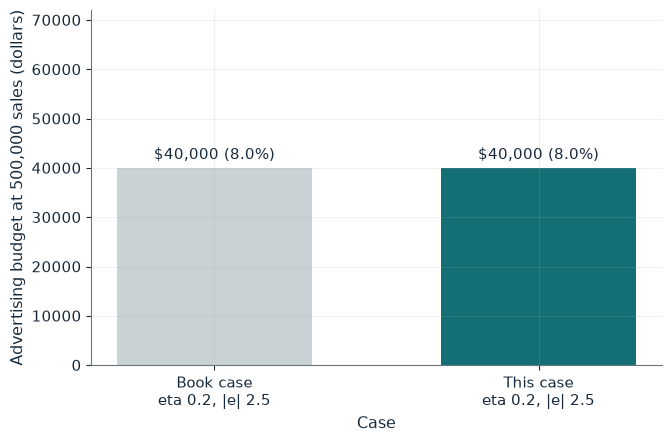

A/PQ = eta_A / |e|             8.0%
Budget at $500,000 sales       $40,000
Price-cost margin 1/|e|        0.40
Contribution per box P/|e|     $20.00
Extra boxes per ad dollar Q_A  0.050
Contribution per ad dollar     $1.00

Worked steps:
  1. A/PQ = 0.2 / 2.5 = 0.080
  2. A = 0.080 x 500,000 = $40,000
  3. Q_A = 0.2 x 10,000 / 40,000 = 0.050
  4. Contribution per box = 50 / 2.5 = $20.00
  5. Contribution per ad dollar = 20.00 x 0.050 = $1.00

A/PQ = 0.2 / 2.5 = 0.080, so the budget is 0.080 x 500,000 = $40,000. At that budget Q_A = 0.2 x 10,000 / 40,000 = 0.050 extra boxes per ad dollar, and each box contributes 50 / 2.5 = $20.00, so the last ad dollar returns 20.00 x 0.050 = $1.00, exactly its cost.


In [2]:
show(ad_budget_picture(eta_a=0.20, eps=2.5))

Change one input, `eta_a`, and hold the others at the book's values:

In [3]:
sweep(ad_budget_picture, 'eta_a', [0.1, 0.2, 0.3], {'eps': 2.5}, ['A/PQ = eta_A / |e|', 'Budget at $500,000 sales'])

eta_a | A/PQ = eta_A / |e| | Budget at $500,000 sales
0.1 | 4.0% | $20,000
0.2 | 8.0% | $40,000
0.3 | 12.0% | $60,000


The budget is 8 percent of \$500,000, or \$40,000. At that budget each ad dollar brings 0.05 extra boxes worth \$20 each, so the last dollar returns exactly \$1. The share is proportional to $\eta_A$ and inversely proportional to $|\varepsilon|$.

## 2. Labor-compute substitution: when expert labor gets expensive

Both mixes reach a score of 76.

$$C_L=8+7=\$15\text{ million}, \qquad C_K=4+14=\$18\text{ million}.$$

If the expert labor price quadruples,

$$C_L'=4(8)+7=\$39\text{ million}, \qquad C_K'=4(4)+14=\$30\text{ million}.$$

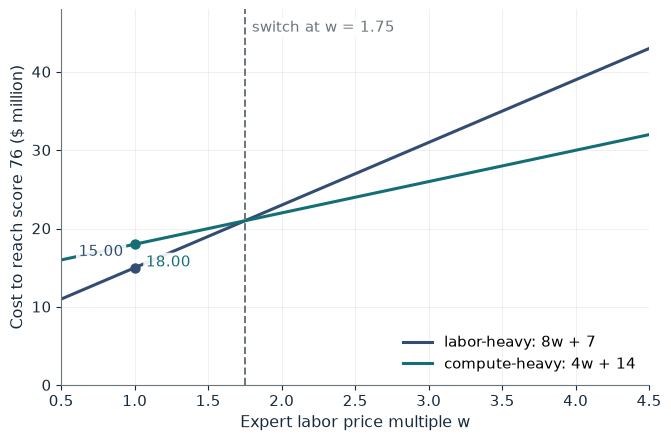

C_L, labor-heavy ($ million)    15.00
C_K, compute-heavy ($ million)  18.00
Cheaper mix                     Labor-heavy mix
Difference ($ million)          3.00

Worked steps:
  1. C_L = 8 x 1 + 7 = 15.00
  2. C_K = 4 x 1 + 14 = 18.00
  3. Difference = 15.00 - 18.00 = -3.00
  4. Switch: 8w + 7 = 4w + 14 gives 4w = 7, w = 1.75

C_L = 8 x 1 + 7 = 15.00 and C_K = 4 x 1 + 14 = 18.00. The labor-heavy mix is cheaper by 3.00 million. The costs are equal where 8w + 7 = 4w + 14, that is w = 7 / 4 = 1.75.


In [4]:
show(mix_picture(wage=1))

Change one input, `wage`, and hold the others at the book's values:

In [5]:
sweep(mix_picture, 'wage', [1, 1.5, 2, 4], {}, ['C_L, labor-heavy ($ million)', 'C_K, compute-heavy ($ million)', 'Cheaper mix'])

wage | C_L, labor-heavy ($ million) | C_K, compute-heavy ($ million) | Cheaper mix
1 | 15.00 | 18.00 | Labor-heavy mix
1.5 | 19.00 | 20.00 | Labor-heavy mix
2 | 23.00 | 22.00 | Compute-heavy mix
4 | 39.00 | 30.00 | Compute-heavy mix


The labor-heavy mix is cheaper until $8w+7=4w+14$, that is $w=1.75$; above that the compute-heavy mix wins.

## 3. Sumptuary laws and Veblen goods: the cost of evasion

Use value is \$40 and status values are $0.2p$, $1.2p$ and $1.4p$.

$$U_L=40+0.2(70)-70=-16,$$

$$U_M=40+1.2(70)-70=54, \qquad U_H=40+1.4(70)-70=68.$$

If only H may display the garment, M's illicit payoff subtracts the expected fine $\rho F$ with $F=100$.

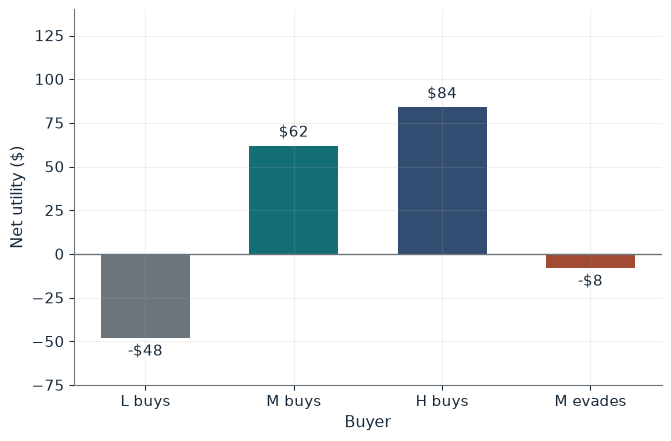

U_L                 -$48
U_M                 $62
U_H                 $84
Expected sanction   $70
M's illicit payoff  -$8
M evades            No

Worked steps:
  1. U_L = 40 + 22 - 110 = -48
  2. U_M = 40 + 132 - 110 = 62
  3. U_H = 40 + 154 - 110 = 84
  4. Expected sanction = 0.7 x 100 = 70
  5. M's illicit payoff = 62 - 70 = -8

At a price of 110: U_L = 40 + 0.2 x 110 - 110 = -48, U_M = 40 + 1.2 x 110 - 110 = 62 and U_H = 40 + 1.4 x 110 - 110 = 84. If only H may display the garment, M's expected sanction is 0.7 x 100 = 70, so its illicit payoff is 62 - 70 = -8: M does not evade.


In [6]:
show(status_picture(price=110, detect=0.70))

Change one input, `price`, and hold the others at the book's values:

In [7]:
sweep(status_picture, 'price', [70, 90, 110], {'detect': 0.7}, ['U_M', "M's illicit payoff", 'M evades'])

price | U_M | M's illicit payoff | M evades
70 | $54 | -$16 | No
90 | $58 | -$12 | No
110 | $62 | -$8 | No


At \$110 M's pre-sanction payoff is \$62; with detection 0.70 the expected sanction is \$70 and evasion pays -\$8, so M complies. With detection 0.20 (`detect=0.20`) the illicit payoff is \$42 and M evades.

## 4. Spence quality distortion: under- or over-provision?

100 subscribers; reliability costs

$$C(s)=20s^2, \qquad C_s(s)=40s.$$

The boundary subscriber values a unit at \$4, so the firm sets

$$400=40s,$$

and $s_M=10$. Users value it at \$7 on average, so $s_W=17.5$.

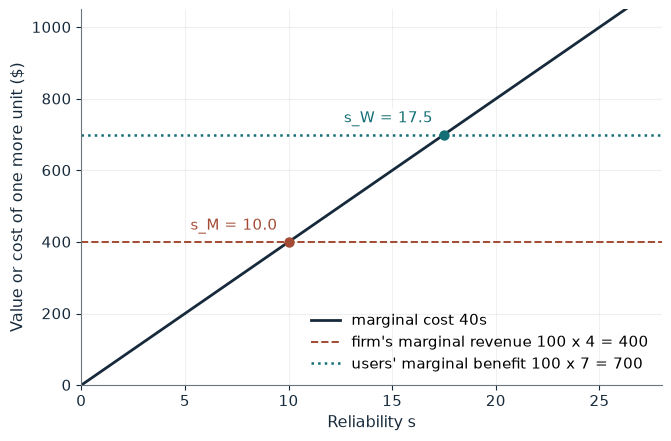

Firm's marginal revenue 100 vb  400
s_M (monopoly)                  10.0
Users' marginal benefit 100 va  700
s_W (welfare)                   17.5
Distortion                      Under-provision

Worked steps:
  1. Firm: 100 x 4 = 400 = 40s
  2. s_M = 400 / 40 = 10.0
  3. Welfare: 100 x 7 = 700 = 40s
  4. s_W = 700 / 40 = 17.5
  5. s_M - s_W = 10.0 - 17.5 = -7.5

The firm sets 100 x 4 = 40s, so s_M = 400 / 40 = 10.0. Welfare sets 100 x 7 = 40s, so s_W = 700 / 40 = 17.5. The monopolist under-provides quality by 7.5 units. At s_M one more unit costs 400 and is worth 700 to users.


In [8]:
show(quality_picture(vb=4, va=7))

Change one input, `vb`, and hold the others at the book's values:

In [9]:
sweep(quality_picture, 'vb', [4, 7, 9], {'va': 7}, ['s_M (monopoly)', 's_W (welfare)', 'Distortion'])

vb | s_M (monopoly) | s_W (welfare) | Distortion
4 | 10.0 | 17.5 | Under-provision
7 | 17.5 | 17.5 | None (tie)
9 | 22.5 | 17.5 | Over-provision


With the boundary value at \$9, $s_M=\frac{900}{40}=22.5$, above $s_W=17.5$: the distortion reverses. When the two valuations are equal there is no distortion.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

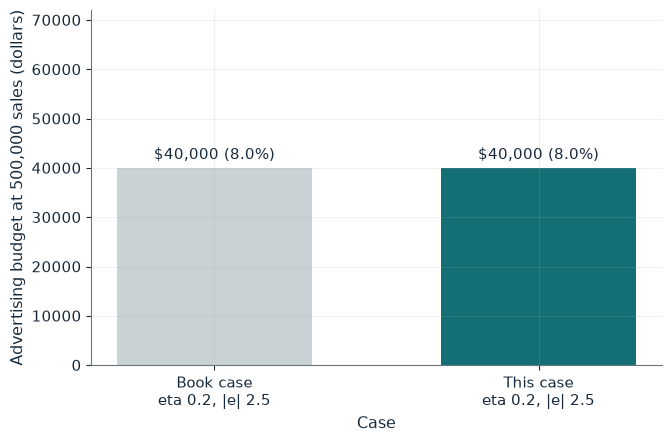

A/PQ = eta_A / |e|             8.0%
Budget at $500,000 sales       $40,000
Price-cost margin 1/|e|        0.40
Contribution per box P/|e|     $20.00
Extra boxes per ad dollar Q_A  0.050
Contribution per ad dollar     $1.00

Worked steps:
  1. A/PQ = 0.2 / 2.5 = 0.080
  2. A = 0.080 x 500,000 = $40,000
  3. Q_A = 0.2 x 10,000 / 40,000 = 0.050
  4. Contribution per box = 50 / 2.5 = $20.00
  5. Contribution per ad dollar = 20.00 x 0.050 = $1.00

A/PQ = 0.2 / 2.5 = 0.080, so the budget is 0.080 x 500,000 = $40,000. At that budget Q_A = 0.2 x 10,000 / 40,000 = 0.050 extra boxes per ad dollar, and each box contributes 50 / 2.5 = $20.00, so the last ad dollar returns 20.00 x 0.050 = $1.00, exactly its cost.


In [10]:
show(ad_budget_picture(eta_a=0.20, eps=2.5))

## Practice

**1.** With $\eta_A=0.30$ and $|\varepsilon|=2.5$, what advertising budget is indicated at \$500,000 of sales?

<details><summary>Answer</summary>

0.30 / 2.5 = 0.12, and 0.12 x 500,000 = \$60,000.

</details>

**2.** At a labor price multiple of 2, which mix is cheaper and by how much?

<details><summary>Answer</summary>

C_L = 8(2) + 7 = 23 and C_K = 4(2) + 14 = 22, so the compute-heavy mix wins by 1 million.

</details>

**3.** With a boundary value of 7 and an average value of 5, what are s_M and s_W?

<details><summary>Answer</summary>

s_M = 700 / 40 = 17.5 and s_W = 500 / 40 = 12.5: over-provision by 5.

</details>